<h1 align="center">Rwanda Maize–Urea Trial</h1>
<h2 align="center">3. Exploratory Data Analysis & Field Map</h2>

**Goal:** see how yield varies by treatment, season and mega-environment before modelling, and map the trial fields (Objective 4).

Raw averages here ignore the fact that plots share fields. We'll do an adjusted comparison later in the analysis.

> **Data note.** The trial data is confidential and is not in this repository. The outputs shown come from the **synthetic sample** in `01_Data/sample/`, which has the same structure and data-quality problems as the real data. The numbers illustrate the method; they are not Evergreen's actual results.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "02_Notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
from IPython.display import Image, display

from maize import config, data, mapping, plotting

pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 30)
MODE = config.data_mode()
OUT = config.output_paths(MODE)
print(
    "Data source:", "confidential trial data (01_Data/raw)" 
    if MODE == "raw" else "synthetic sample (01_Data/sample)"
    )

Data source: synthetic sample (01_Data/sample)


In [2]:
_, combined = data.build_combined(MODE)
df = data.analysis_frame(combined)
ok = df[~df["flag_implausible_yield"]]
print(
    f"{len(df)} plots with field context; {len(ok)} after setting aside the implausible yield"
    )

1582 plots with field context; 1581 after setting aside the implausible yield


## 1. Yield by treatment

In [3]:
(ok.groupby("urea_rate_timing", observed=True)["yield_tha"]
   .agg(plots="size", mean="mean", median="median", sd="std")
   .rename(index=config.TREATMENT_LABELS))

,plots,mean,median,sd
urea_rate_timing,,,,
"A: 50 kg/ha, all at V6",397,4.943,4.90,1.563
"B: 100 kg/ha, planting + V6",392,4.989,4.87,1.594
"C: 100 kg/ha, V6 + V10",396,5.316,5.20,1.606
"D: 100 kg/ha, all at V6",396,5.494,5.37,1.572


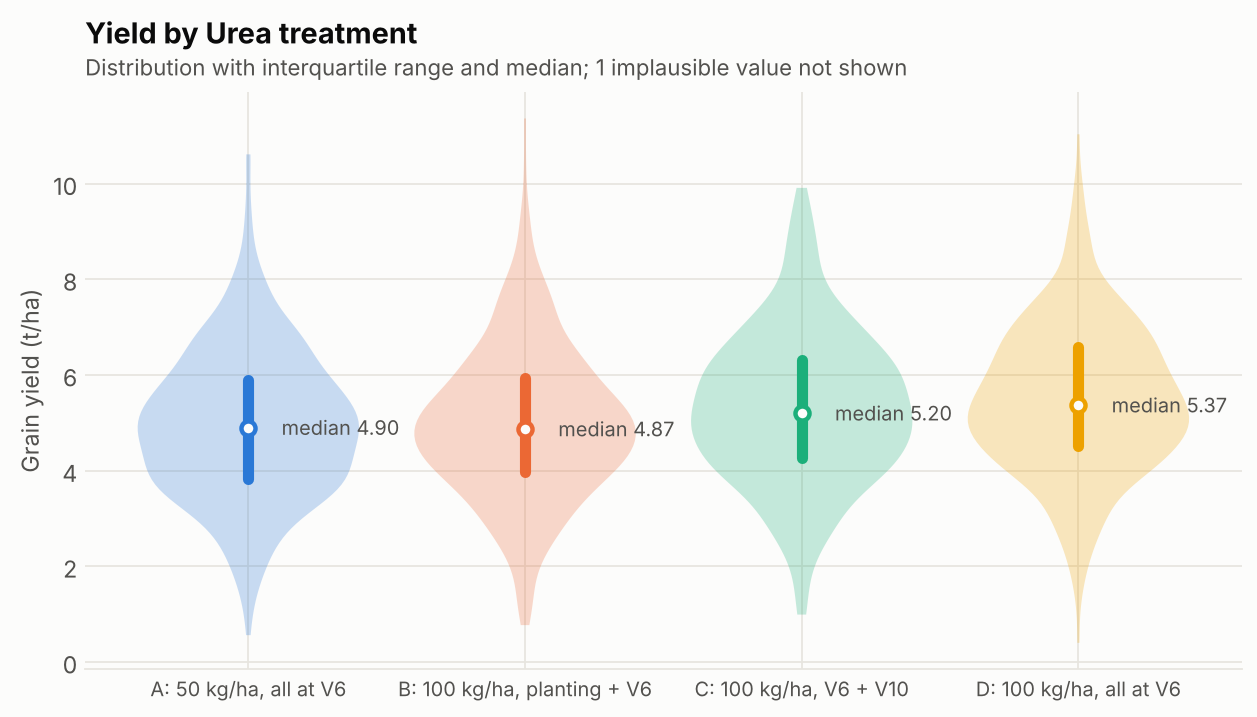

In [4]:
plotting.yield_by_treatment(df, OUT.figures / "yield_by_treatment.png")
display(Image(OUT.figures / "yield_by_treatment.png", width=700))

Both treatments that apply 100 kg/ha at V6 or later (C and D) sit visibly higher than the baseline. Splitting with a planting dose (B) barely moves the distribution. The spread within each treatment (SD about 1.6 t/ha) is much larger than the gaps between them, which is why a model that accounts for field differences is needed.

## 2. By season

In [5]:
(ok.pivot_table(index="season", columns="urea_rate_timing", values="yield_tha", aggfunc="mean", observed=True)
   .rename(columns=config.SHORT_LABELS))

urea_rate_timing,A · 50 kg V6,B · 100 kg Plant+V6,C · 100 kg V6+V10,D · 100 kg V6
season,,,,
21A,4.618,4.764,5.081,5.254
22A,5.147,5.188,5.474,5.654
22B,4.961,4.862,5.304,5.483


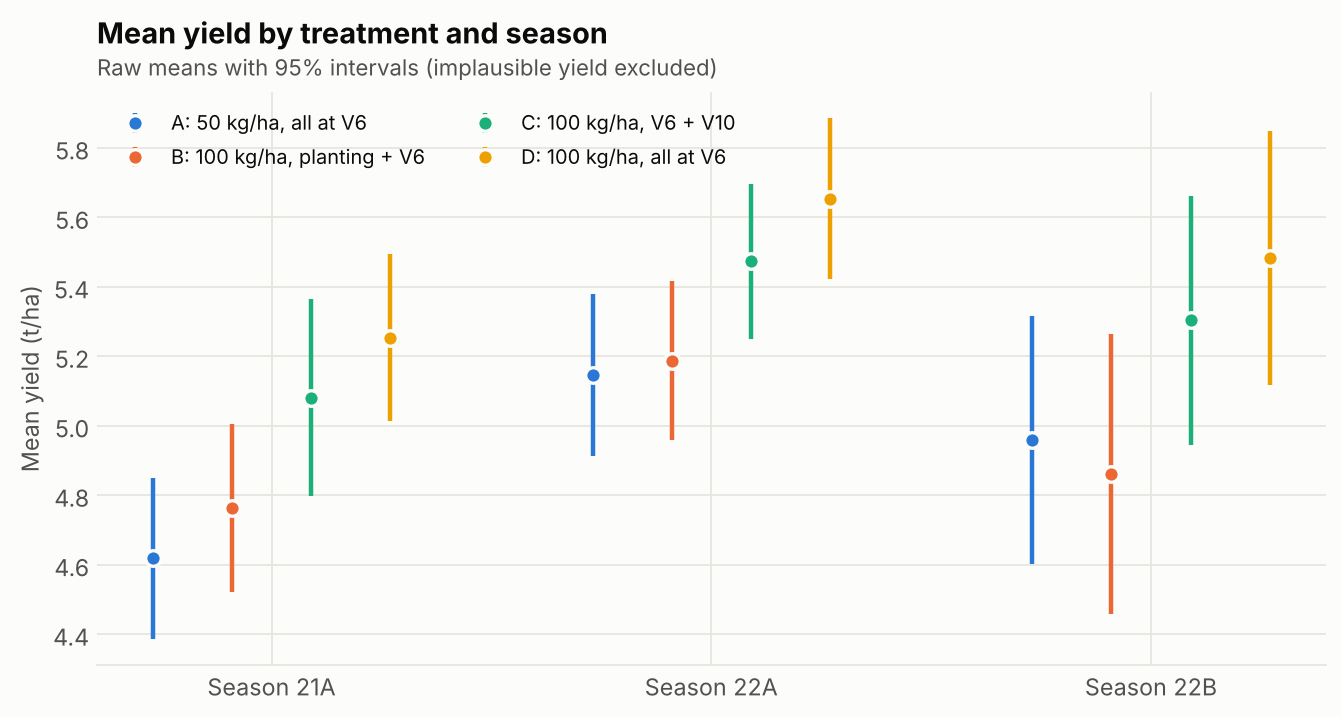

In [6]:
plotting.yield_by_treatment_season(df, OUT.figures / "yield_by_treatment_and_season.png")
display(Image(OUT.figures / "yield_by_treatment_and_season.png", width=720))

The ranking is consistent across seasons: D and C on top, with A and B close together at the bottom. 22A was the best season overall.

## 3. By mega-environment

In [7]:
(ok.pivot_table(index="meg_env", columns="urea_rate_timing", values="yield_tha", aggfunc="mean", observed=True)
   .rename(columns=config.SHORT_LABELS)
   .assign(fields=ok.groupby("meg_env")["field_season_id"].nunique()))

urea_rate_timing,A · 50 kg V6,B · 100 kg Plant+V6,C · 100 kg V6+V10,D · 100 kg V6,fields
meg_env,,,,,
Highlands,4.717,4.678,5.003,5.224,142
Low-Mid-Dry,5.820,5.914,6.170,6.414,114
Low-Mid-Wet,4.408,4.434,4.901,5.032,77
Transitional,4.524,4.728,4.982,5.006,64


Low-Mid-Dry fields yield about 1.2–1.4 t/ha more than the others regardless of treatment. Within every environment the 100 kg/ha treatments applied at V6 or later lead. We want to test whether these differences are significant later in our analysis.

## 4. Map of trial fields (Objective 4)

Published maps round coordinates to 2 decimal places (~1 km) to protect farmers. An exact map is written only to the git-ignored `01_Data/processed/` folder.

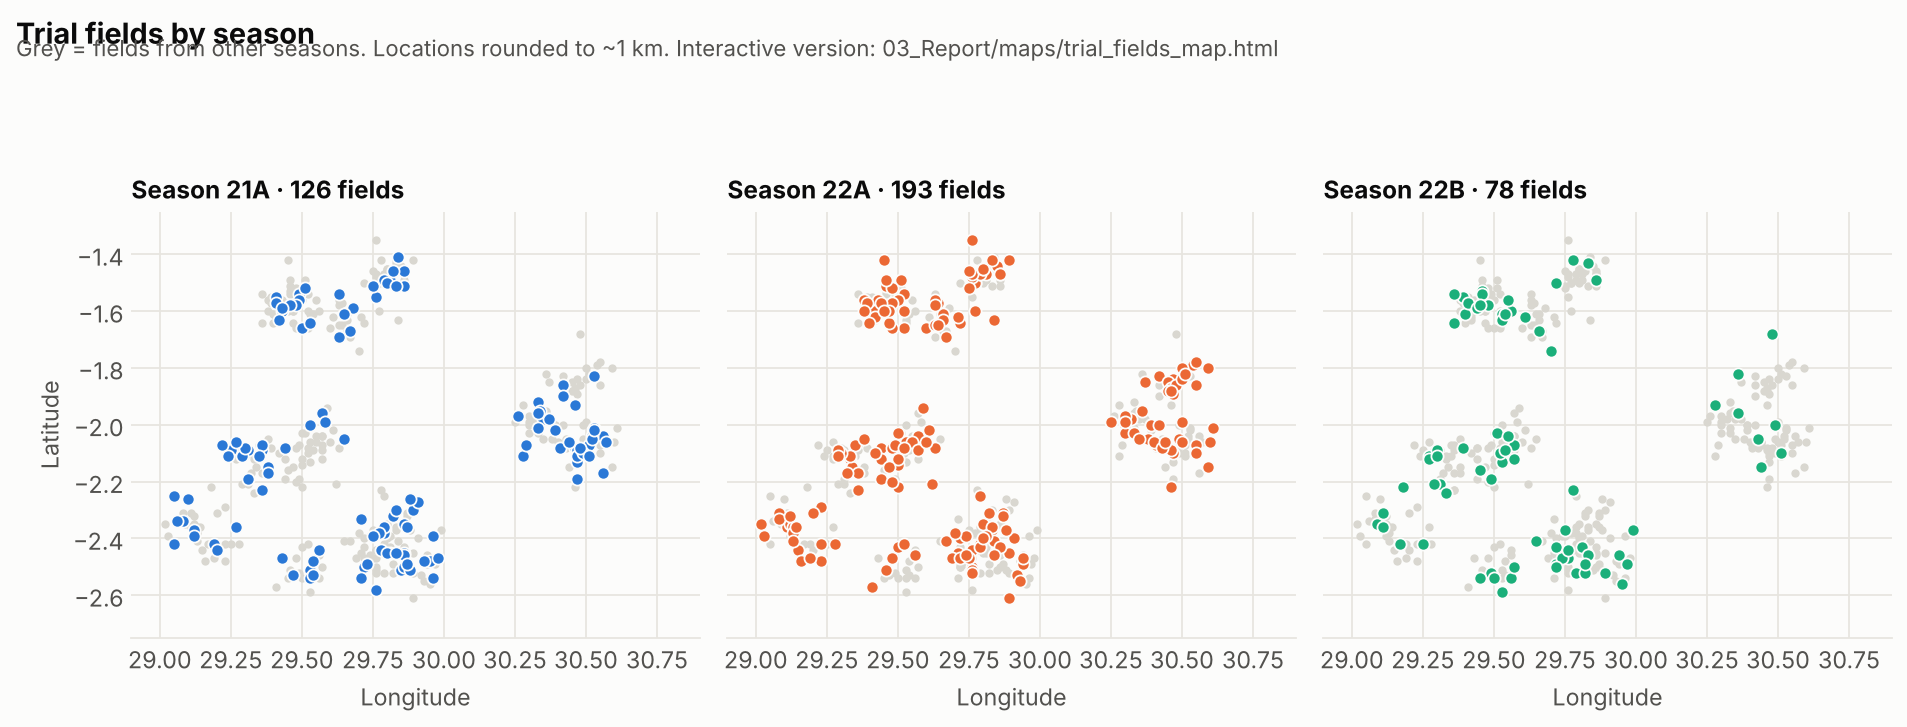

,fields,districts
season,,
21A,126,14
22A,193,14
22B,78,14


In [8]:
mapping.static_map(combined, OUT.figures / "trial_fields_map.png")
mapping.interactive_map(combined, OUT.maps / "trial_fields_map.html")
display(Image(OUT.figures / "trial_fields_map.png", width=900))
mapping.field_points(combined).groupby("season").agg(fields=("district", "size"), districts=("district", "nunique"))

The interactive version ([`03_Report/maps/trial_fields_map.html`](../03_Report/maps/trial_fields_map.html)) lets you toggle seasons and hover for district, environment and median yield.

All three seasons cover the same 14 districts, but 22B has far fewer fields (78, against 126 in 21A and 193 in 22A), so its season estimates are less precise.

**Next:** notebook 04 estimates the treatment effects properly.